# 05 - Final models, interpretation and test labels

**Goal:** fit the models chosen in notebook 04 on all training students, understand what they learned and where they fail, and produce the labels for the test set.

**Inputs:** `data/raw/*.csv` through `miopia.data.load_raw()`, `final_model` from `miopia.models`, and the estimates saved in `results/experiments/nested_protocol.json`.

**Outputs:** `results/test_labels.txt` and the figures `05_*.png`.

**Assumptions touched:** A1 and A2 (format of the labels), B2, B3 and B14, see `docs/assumptions.md`. **The test set is used once, in section 5, only to predict.** Nothing in this notebook is chosen from it, and no output depends on knowing its labels, which we do not have.

## 1. Setup and data loading

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.special import logit
from scipy.stats import binom
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold

from miopia.config import RANDOM_STATE, RESULTS
from miopia.data import load_raw
from miopia.features import clean_features, with_axial_corneal_ratio
from miopia.models import final_model
from miopia.plotting import BLUE, SEQUENTIAL_CMAP, save_fig, set_style
from miopia.validation import SUMMARY_METRICS, evaluate, make_strata

set_style()
pd.set_option("display.width", 160)
TARGETS = ["M", "MM", "Combo", "DCombo"]
RATIO = "axial_corneal_ratio"
X_train_raw, Y_train, X_test_raw = load_raw()
clean_train = clean_features(X_train_raw)
FEATURES = list(clean_train.columns)
X_train = with_axial_corneal_ratio(clean_train)
print(f"train {X_train.shape}")

train (132, 34)


## 2. What are the final models?

**What and why:** each model from `final_model` is fitted on all 132 training students, because more students give a better final model. Its settings, including the `MM` threshold and the `Combo` forest's hyperparameters, are chosen again inside these training students. The scores of the notebook 04 comparison do not come from these fits; they come from cross-validation.

In [2]:
fitted, columns = {}, {}
for target in TARGETS:
    model, columns[target] = final_model(target, FEATURES)
    fitted[target] = model.fit(X_train[columns[target]], Y_train[target])

mm_logistic = fitted["MM"].estimator_
scale, logistic = mm_logistic.named_steps["prep"].named_steps["scale"], mm_logistic.named_steps["model"]
threshold = fitted["MM"].best_threshold_
ratio_cut = scale.mean_[0] + scale.scale_[0] * (logit(threshold) - logistic.intercept_[0]) / logistic.coef_[0, 0]
print(f"MM: threshold {threshold:.2f}, which means saying SI above a ratio of {ratio_cut:.2f}")
print(f"MM training students above that cut: {(X_train[RATIO] > ratio_cut).sum()} of {len(X_train)}")
print("Combo forest settings:", {k.removeprefix("model__"): v for k, v in fitted["Combo"].best_params_.items()})

MM: threshold 0.66, which means saying SI above a ratio of 3.32
MM training students above that cut: 12 of 132
Combo forest settings: {'max_features': 0.5, 'min_samples_leaf': 1}


## 3. What did the models learn?

**What and why:** three of the models are logistic regressions on one or two standardised inputs, so their coefficients can be read directly: a larger size means a stronger effect per standard deviation. For `DCombo` there is one row per class. Axial length and the ratio are correlated, so each coefficient must be read with the other held fixed, and not as a separate cause.

In [3]:
rows = {"M, says SI": dict(zip(columns["M"], fitted["M"].named_steps["model"].coef_[0])),
        "MM, says SI": dict(zip(columns["MM"], logistic.coef_[0]))}
dcombo = fitted["DCombo"].named_steps["model"]
rows.update({f"DCombo, says {c}": dict(zip(columns["DCombo"], dcombo.coef_[i])) for i, c in enumerate(dcombo.classes_)})
print(f"Spearman correlation of axial length and ratio: {X_train[['axial_length', RATIO]].corr(method='spearman').iloc[0, 1]:.2f}")
pd.DataFrame(rows).T.round(2)

Spearman correlation of axial length and ratio: 0.72


,axial_length,axial_corneal_ratio
"M, says SI",0.89,1.85
"MM, says SI",NaN,1.37
"DCombo, says C",-1.65,-1.73
"DCombo, says M1",-1.07,-0.45
"DCombo, says M2",-0.05,0.95
"DCombo, says MM",2.78,1.23


The `Combo` random forest has no coefficients, so we measure permutation importance: how much balanced accuracy drops on validation students when one feature is shuffled. It is measured on held-out students, because importance on the training rows would be inflated. The forest and its settings are refitted in each training fold. Each dot is one validation fold, and features that are almost duplicates share their importance, so the four keratometry values cannot be read one by one (notebook 02).

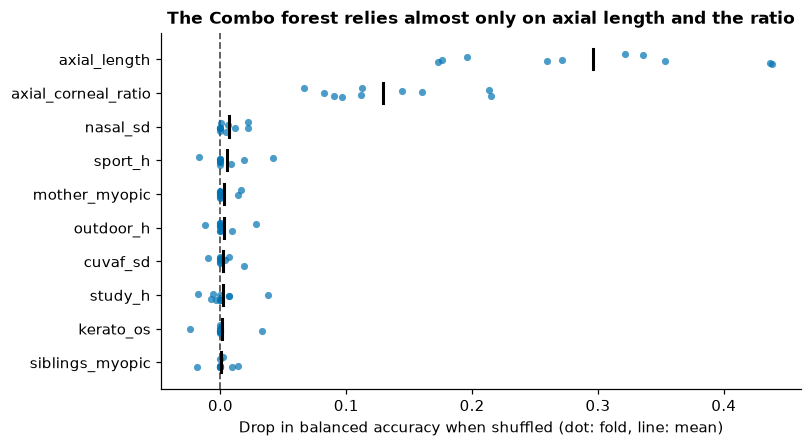

,mean drop in balanced accuracy
axial_length,0.296
axial_corneal_ratio,0.129
nasal_sd,0.007
sport_h,0.005
mother_myopic,0.003
outdoor_h,0.003
cuvaf_sd,0.002
study_h,0.002
kerato_os,0.001
siblings_myopic,0.001


In [4]:
y_combo = Y_train["Combo"]
data = X_train[columns["Combo"]]
importances = []
for train, val in RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE).split(data, y_combo):
    model = clone(final_model("Combo", FEATURES)[0]).fit(data.iloc[train], y_combo.iloc[train])
    result = permutation_importance(model, data.iloc[val], y_combo.iloc[val], scoring="balanced_accuracy", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    importances.append(pd.Series(result.importances_mean, index=data.columns))
importances = pd.DataFrame(importances)
order = importances.mean().sort_values(ascending=False).index[:10]

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for y, feature in enumerate(order):
    ax.scatter(importances[feature], y + rng.uniform(-0.15, 0.15, len(importances)), s=22, color=BLUE, alpha=0.7, linewidths=0)
    ax.plot([importances[feature].mean()] * 2, [y - 0.3, y + 0.3], color="black", lw=2)
ax.axvline(0, color="0.35", ls="--", lw=1.2, zorder=0)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlabel("Drop in balanced accuracy when shuffled (dot: fold, line: mean)")
ax.set_title('The Combo forest relies almost only on axial length and the ratio')
save_fig(fig, "05_combo_importance")
plt.show()
importances.mean().sort_values(ascending=False).head(10).round(3).to_frame("mean drop in balanced accuracy")

**Findings.** The models tell a simple and consistent story: myopia rises with a longer eye and with a higher axial/corneal ratio. On `DCombo`, both coefficients go from clearly negative for controls to clearly positive for myopia magna. On `MM`, the threshold means saying `SI` only above a high ratio, close to the mean of the students with `DCombo = MM`. The `Combo` forest has access to all the features, but on validation students almost all of its performance comes from axial length and the ratio; shuffling any other feature changes little. This does not mean that family history or time outdoors have no effect on myopia: this is a sample of 132 students, and these features may act through the length of the eye, which is measured directly. Coefficients and importances describe what the models use, not what causes myopia.

## 4. Where do the final models fail?

**What and why:** errors are measured on validation students, with the same 5-fold, 10-repeat scheme, so that no student is judged by a model that was trained on them. The panels show, for each true class, the share of predictions given to each class.

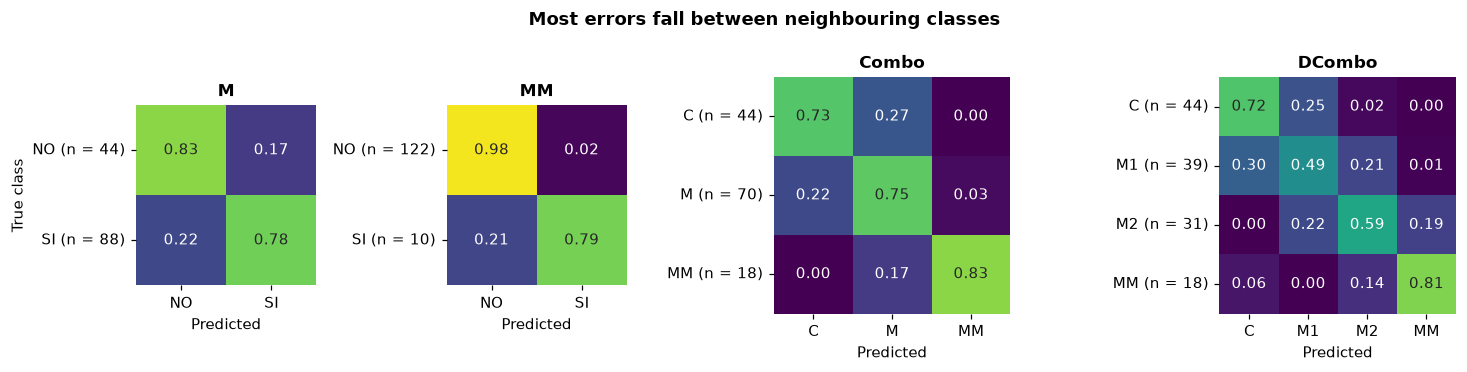

In [5]:
frames, predictions = {}, {}
for target in TARGETS:
    model, cols = final_model(target, FEATURES)
    frames[target], predictions[target] = evaluate(model, X_train[cols], Y_train[target], Y_train[target], make_strata(Y_train, target))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), gridspec_kw={"width_ratios": [2, 2, 3, 4]})
for ax, target in zip(axes, TARGETS):
    classes = sorted(Y_train[target].unique())
    truth = np.repeat(Y_train[target].to_numpy(), predictions[target].shape[1])
    matrix = confusion_matrix(truth, predictions[target].ravel(), labels=classes, normalize="true")
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap=SEQUENTIAL_CMAP, vmin=0, vmax=1, cbar=False, square=True, xticklabels=classes, yticklabels=classes, ax=ax)
    counts = Y_train[target].value_counts()
    ax.set_yticklabels([f"{c} (n = {counts[c]})" for c in classes], rotation=0)
    ax.set_xlabel("Predicted")
    ax.set_title(target)
axes[0].set_ylabel("True class")
fig.suptitle('Most errors fall between neighbouring classes', fontweight="bold")
fig.tight_layout()
save_fig(fig, "05_confusion")
plt.show()

Since the classes of `DCombo` are ordered, the first table shows how far its errors go. The second shows how the `M` errors spread over the severity groups, and whether they concentrate near the boundary.

In [6]:
position = {c: i for i, c in enumerate(["C", "M1", "M2", "MM"])}
distance = np.abs(np.vectorize(position.get)(predictions["DCombo"]) - Y_train["DCombo"].map(position).to_numpy()[:, None])
display(pd.Series({"correct": (distance == 0).mean(), "off by one class": (distance == 1).mean(), "off by two or more": (distance >= 2).mean()}, name="DCombo predictions").round(2).to_frame())

wrong = predictions["M"] != Y_train["M"].to_numpy()[:, None]
pd.DataFrame({"students": Y_train.groupby("DCombo").size(), "mean ratio": X_train.groupby(Y_train["DCombo"])[RATIO].mean(),
              "M error rate": pd.Series(wrong.mean(axis=1), index=Y_train.index).groupby(Y_train["DCombo"]).mean()}).round(2)

,DCombo predictions
correct,0.63
off by one class,0.35
off by two or more,0.02


,students,mean ratio,M error rate
DCombo,,,
C,44,3.01,0.17
M1,39,3.10,0.46
M2,31,3.23,0.00
MM,18,3.32,0.06


**Findings.** Most errors fall between neighbouring classes. On `DCombo`, about one prediction in three is off by one class and very few are off by more, so the model usually gets the severity about right but not exactly. `M1` is the hardest class, because it sits between controls and `M2`, and its ratio is close to that of controls. For the same reason, the `M` model calls almost half of the `M1` students not myopic, while it never misses an `M2` student. The errors suggest that the boundary between mild myopia and no myopia is the weakest point of these measurements, as could be expected without a direct measure of refraction. On `MM`, the model almost never gives a false alarm, but it misses about one positive in five: this is the price of the threshold chosen in notebook 04, and in a clinical setting, where a missed case costs more, a lower threshold would be preferable.

## 5. What are the labels for the test set?

**What and why:** this is the only place where the test students are predicted. The same row-wise cleaning is applied to them, and anything that was learned, such as medians, scaling, thresholds and hyperparameters, comes from the training students. The file follows A1 and A2: one column per target, separated by tabs, with a header and one row per test student in the order of `X_test.csv`, and the labels written as in `Y_train.csv` (`SI`/`NO`), although the brief says YES/NO. Individual predictions are not printed here, to keep student data out of the report.

In [7]:
X_test = with_axial_corneal_ratio(clean_features(X_test_raw))
test_labels = pd.DataFrame({t: fitted[t].predict(X_test[columns[t]]) for t in TARGETS})
path = RESULTS / "test_labels.txt"
test_labels.to_csv(path, sep="\t", index=False)

check = pd.read_csv(path, sep="\t")
assert check.equals(test_labels) and len(check) == len(X_test_raw) and list(check.columns) == TARGETS
for target in TARGETS:
    assert set(check[target]) <= set(Y_train[target]), target
print(f"wrote {path.name}: {len(check)} rows, columns {list(check.columns)}, no missing values: {check.notna().all().all()}")

wrote test_labels.txt: 24 rows, columns ['M', 'MM', 'Combo', 'DCombo'], no missing values: True


Two checks on the file, neither of which changes any label. The first compares the predicted share of each class with its share in the training labels, since a very different mix would point to a problem. The second counts the contradictions between targets promised in notebook 04, with no prediction forced to agree (B3).

In [8]:
shares = pd.concat({t: pd.DataFrame({"test, predicted": test_labels[t].value_counts(normalize=True),
                                     "train, true": Y_train[t].value_counts(normalize=True)}) for t in TARGETS}).fillna(0).round(2)
display(shares)

m, mm, combo, dc = (test_labels[t] for t in TARGETS)
contradictions = {
    "M = NO but Combo is not C": (m == "NO") & (combo != "C"),
    "M = SI but Combo = C": (m == "SI") & (combo == "C"),
    "MM = SI but Combo is not MM": (mm == "SI") & (combo != "MM"),
    "MM = SI but M = NO": (mm == "SI") & (m == "NO"),
    "Combo and DCombo disagree on C": (combo == "C") != (dc == "C"),
    "Combo and DCombo disagree on MM": (combo == "MM") != (dc == "MM"),
    "For information: Combo = MM and MM = NO": (combo == "MM") & (mm == "NO"),
}
pd.Series({k: int(v.sum()) for k, v in contradictions.items()}, name=f"test students, of {len(test_labels)}").to_frame()

test, predicted  train, true
M      SI             0.54         0.67
       NO             0.46         0.33
MM     NO             0.79         0.92
       SI             0.21         0.08
Combo  M              0.42         0.53
       C              0.38         0.33
       MM             0.21         0.14
DCombo C              0.42         0.33
       M1             0.21         0.30
       M2             0.17         0.23
       MM             0.21         0.14

,"test students, of 24"
M = NO but Combo is not C,2
M = SI but Combo = C,0
MM = SI but Combo is not MM,0
MM = SI but M = NO,0
Combo and DCombo disagree on C,3
Combo and DCombo disagree on MM,0
For information: Combo = MM and MM = NO,0


The predicted share of `MM = SI` stands out, so the next cell looks at why, using only the measurements of the test students. Nothing here changes a label: adjusting them after looking at the test set would break the rule of this notebook.

In [9]:
keratometry = ["kerato_od", "kerato_od_axis2", "kerato_os", "kerato_os_axis2"]
measures = pd.DataFrame({"train": [X_train["axial_length"].mean(), X_train[keratometry].mean(axis=1).mean(), X_train[RATIO].mean(), (X_train[RATIO] > ratio_cut).mean()],
                         "test": [X_test["axial_length"].mean(), X_test[keratometry].mean(axis=1).mean(), X_test[RATIO].mean(), (X_test[RATIO] > ratio_cut).mean()]},
                        index=["axial length (mm)", "keratometry (D)", "ratio", f"share with ratio above {ratio_cut:.2f}"]).round(2)
display(measures)
n_positive, rate = int((test_labels["MM"] == "SI").sum()), (X_train[RATIO] > ratio_cut).mean()
print(f"Chance of {n_positive} or more of {len(test_labels)} above the cut, if the training rate of {rate:.2f} holds: {binom.sf(n_positive - 1, len(test_labels), rate):.2f}")

,train,test
axial length (mm),24.41,24.56
keratometry (D),43.30,43.03
ratio,3.13,3.13
share with ratio above 3.32,0.09,0.21


Chance of 5 or more of 24 above the cut, if the training rate of 0.09 holds: 0.06


**Findings.** The file has the expected shape and contains only valid labels. Most contradictions between targets are in the expected places: a few students have `M = NO` while `Combo` is not `C`, or `Combo` and `DCombo` disagree on controls, and no student has `MM = SI` with `M = NO`. They are left as predicted.

The model says `MM = SI` for clearly more test students than the share in the training labels. The measurements explain why: the mean ratio is the same in train and test, but more test students are above the cut. With the training rate this would be uncommon but not rare, as the printed chance shows, and 24 students is a small sample. There are two readings, and we cannot tell them apart: the test set may hold more severe cases, or some of these may be false alarms, which would lower the accuracy of `MM`. *Decision: the labels stay as predicted.* Changing them because of this would be choosing with the test set.

## 6. What accuracy should we expect on the test set?

**What and why:** accuracy is what the test labels are graded on, so here is an honest range for each target before they are graded. *Cross-validation* scores the final model chosen on all students, which is optimistic. *Whole selection* repeats the choice inside each fold (notebook 04, section 11), which is more sober. On `Combo`, that estimate uses a simpler forest and does not describe the chosen model, so it is not shown. With 24 test students, one student is worth about 0.04.

In [10]:
nested = json.loads((RESULTS / "experiments" / "nested_protocol.json").read_text())["means"]
expected = pd.DataFrame({t: {"majority class": Y_train[t].value_counts(normalize=True).max(),
                             "cross-validation, final model": frames[t]["accuracy"].mean(),
                             "whole selection": np.nan if t == "Combo" else nested[t]["whole protocol accuracy"],
                             "fold standard deviation": frames[t]["accuracy"].std(),
                             "balanced accuracy, final model": frames[t]["balanced_accuracy"].mean()} for t in TARGETS}).T.round(2)
expected.astype(object).where(expected.notna(), "")

,majority class,"cross-validation, final model",whole selection,fold standard deviation,"balanced accuracy, final model"
M,0.67,0.8,0.79,0.08,0.8
MM,0.92,0.97,0.92,0.03,0.89
Combo,0.53,0.75,,0.08,0.77
DCombo,0.33,0.63,0.57,0.06,0.65


**Findings.** Every model is expected to beat its majority class on accuracy, except that on `MM` the honest range goes from about the majority class to above it. The other three targets are clearly above it, also in the more sober estimate where there is one. With 24 students, a single test score could easily fall one or two students to either side of these figures, so a test result near these ranges would not be surprising in either direction.

## 7. Summary

| # | Finding | Decision / action |
|---|---|---|
| 1 | The models rely on axial length and the axial/corneal ratio; other features add little on validation students | Described as what the models use, not as causes |
| 2 | Most errors fall between neighbouring classes, and `M1` is the hardest | Reported as a limit of having no direct measure of refraction |
| 3 | `MM` misses about one positive in five | Kept, as the choice made for accuracy; a lower threshold would suit a clinical use |
| 4 | `results/test_labels.txt` has been written, with a few contradictions between targets | Left as predicted (B3) and reported |
| 5 | `MM = SI` is predicted for more test students than expected, because more of them are above the cut | Not changed; it is a risk for the accuracy of `MM` |
| 6 | The expected accuracy is above the majority class on `M`, `Combo` and `DCombo`, and from about level to above it on `MM` | The range in section 6 is what we state before the labels are graded |

The test set was used once, to predict, and no decision depends on it. The format of the file follows A1 and A2, which the brief leaves open.

**Next:** slides, the video and the submission package.